# 00b — Conformal Risk Bands (SPCI-style)

Post-hoc prediction intervals for J01 vol/risk champions with **coverage diagnostics under regime shift**.

**Method:** split-conformal calibration on the validation partition (2018-2019) with a non-overlapping block bootstrap (21-day blocks) to respect serial dependence, following the SPCI recipe. Lower/upper residual quantiles are calibrated **asymmetrically** — volatility under-prediction (the risky side for the product) gets its own tail estimate.

**Why this matters for the product:** instead of a point `risk_score`, the turbulence alert can ship a band ("expected |return| between L and U at 90% coverage"). The *coverage gap* on the COVID test window doubles as a crisis / distribution-shift detector.

**Inputs:** `data/models/*_predictions.json` (no retraining — pure post-processing)

**Outputs:** `data/models/*_conformal.json`

**Kernel:** select **`Python (stock-prediction)`** in the kernel picker (register with `bash scripts/install-jupyter-kernel.sh` if missing).

## 1) Setup and configuration

`ARTIFACTS` lists the prediction JSONs to calibrate. Add or swap entries as champions change.

In [1]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from paths import find_project_root
from conformal import conformal_from_artifact

PROJECT_ROOT = find_project_root()
MODELS_DIR = PROJECT_ROOT / "data" / "models"

ALPHA = 0.10          # 90% target coverage
BLOCK_SIZE = 21       # trading-month blocks for the bootstrap
N_BOOT = 200
SEED = 42

# Candidates to calibrate: champion + strongest challengers per universe.
ARTIFACTS = [
    # dev200
    "garchgru_vol_risk_stocks_dev200_tf_predictions.json",
    "xgb_vol_risk_stocks_dev200_tf_predictions.json",
    "baseline_vol_risk_stocks_dev200_tf_predictions.json",
    "garchgru_vol_risk_etfs_dev200_tf_predictions.json",
    "xgb_vol_risk_etfs_dev200_tf_predictions.json",
    "baseline_vol_risk_etfs_dev200_tf_predictions.json",
    # full universe (stocks)
    "baseline_vol_risk_stocks_tf_predictions.json",
    "garchgru_vol_risk_stocks_tf_predictions.json",
    "garchgru_qlike_vol_risk_stocks_tf_predictions.json",
]
ARTIFACTS = [a for a in ARTIFACTS if (MODELS_DIR / a).exists()]
print(f"Calibrating {len(ARTIFACTS)} artifact(s) at {1 - ALPHA:.0%} target coverage")
for a in ARTIFACTS:
    print(f"- {a}")

Calibrating 6 artifact(s) at 90% target coverage
- garchgru_vol_risk_stocks_dev200_tf_predictions.json
- xgb_vol_risk_stocks_dev200_tf_predictions.json
- baseline_vol_risk_stocks_dev200_tf_predictions.json
- garchgru_vol_risk_etfs_dev200_tf_predictions.json
- xgb_vol_risk_etfs_dev200_tf_predictions.json
- baseline_vol_risk_etfs_dev200_tf_predictions.json


## 2) Calibrate intervals and save `*_conformal.json`

Calibration set = validation partition (2018-2019). Test = Q1-2020 COVID window.

In [2]:
results = {}
for artifact in ARTIFACTS:
    payload = conformal_from_artifact(
        MODELS_DIR, artifact, alpha=ALPHA, block_size=BLOCK_SIZE, n_boot=N_BOOT, seed=SEED
    )
    out_name = artifact.replace("_predictions.json", "_conformal.json")
    with open(MODELS_DIR / out_name, "w") as f:
        json.dump(payload, f, indent=2)
    results[artifact] = payload
    print(f"Saved {out_name}")

Saved garchgru_vol_risk_stocks_dev200_tf_conformal.json


Saved xgb_vol_risk_stocks_dev200_tf_conformal.json


Saved baseline_vol_risk_stocks_dev200_tf_conformal.json
Saved garchgru_vol_risk_etfs_dev200_tf_conformal.json


Saved xgb_vol_risk_etfs_dev200_tf_conformal.json
Saved baseline_vol_risk_etfs_dev200_tf_conformal.json


## 3) Coverage diagnostics

`coverage gap` = target coverage minus empirical coverage on the COVID window. A large gap means the crisis distribution shifted away from calibration — usable as a regime-shift alarm. `undercoverage` = share of crisis days where true vol exceeded the upper band (missed risk).

In [3]:
rows = []
for artifact, payload in results.items():
    c = payload["conformal"]
    rows.append(
        {
            "artifact": artifact.replace("_dev200_tf_predictions.json", ""),
            "architecture": payload["architecture"],
            "universe": payload["universe"],
            "target_coverage": c["target_coverage"],
            "covid_coverage": c["empirical_coverage"],
            "coverage_gap": c["target_coverage"] - c["empirical_coverage"],
            "undercoverage_rate": c["undercoverage_rate"],
            "mean_band_width": c["mean_interval_width"],
        }
    )
diag = pd.DataFrame(rows).sort_values(["universe", "covid_coverage"], ascending=[True, False])
display(diag)

print(
    "Reading: all models lose coverage in the COVID window — the calibration\n"
    "distribution (2018-19) does not contain crisis-scale moves. The size of the\n"
    "gap is a model-agnostic distribution-shift signal for the product's regime gate."
)

,artifact,architecture,universe,target_coverage,covid_coverage,coverage_gap,undercoverage_rate,mean_band_width
4,xgb_vol_risk_etfs,xgb,etfs,0.9,0.693675,0.206325,0.239014,0.018582
5,baseline_vol_risk_etfs,baseline,etfs,0.9,0.677419,0.222581,0.178181,0.020285
3,garchgru_vol_risk_etfs,garchgru,etfs,0.9,0.675133,0.224867,0.205486,0.018871
0,garchgru_vol_risk_stocks,garchgru,stocks,0.9,0.739759,0.160241,0.155274,0.057212
1,xgb_vol_risk_stocks,xgb,stocks,0.9,0.737327,0.162673,0.169739,0.058142
2,baseline_vol_risk_stocks,baseline,stocks,0.9,0.732719,0.167281,0.145033,0.057918


Reading: all models lose coverage in the COVID window — the calibration
distribution (2018-19) does not contain crisis-scale moves. The size of the
gap is a model-agnostic distribution-shift signal for the product's regime gate.


## 4) Visualize risk bands on the COVID window

Sorted by true vol so band adequacy in the tail (right side) is visible.

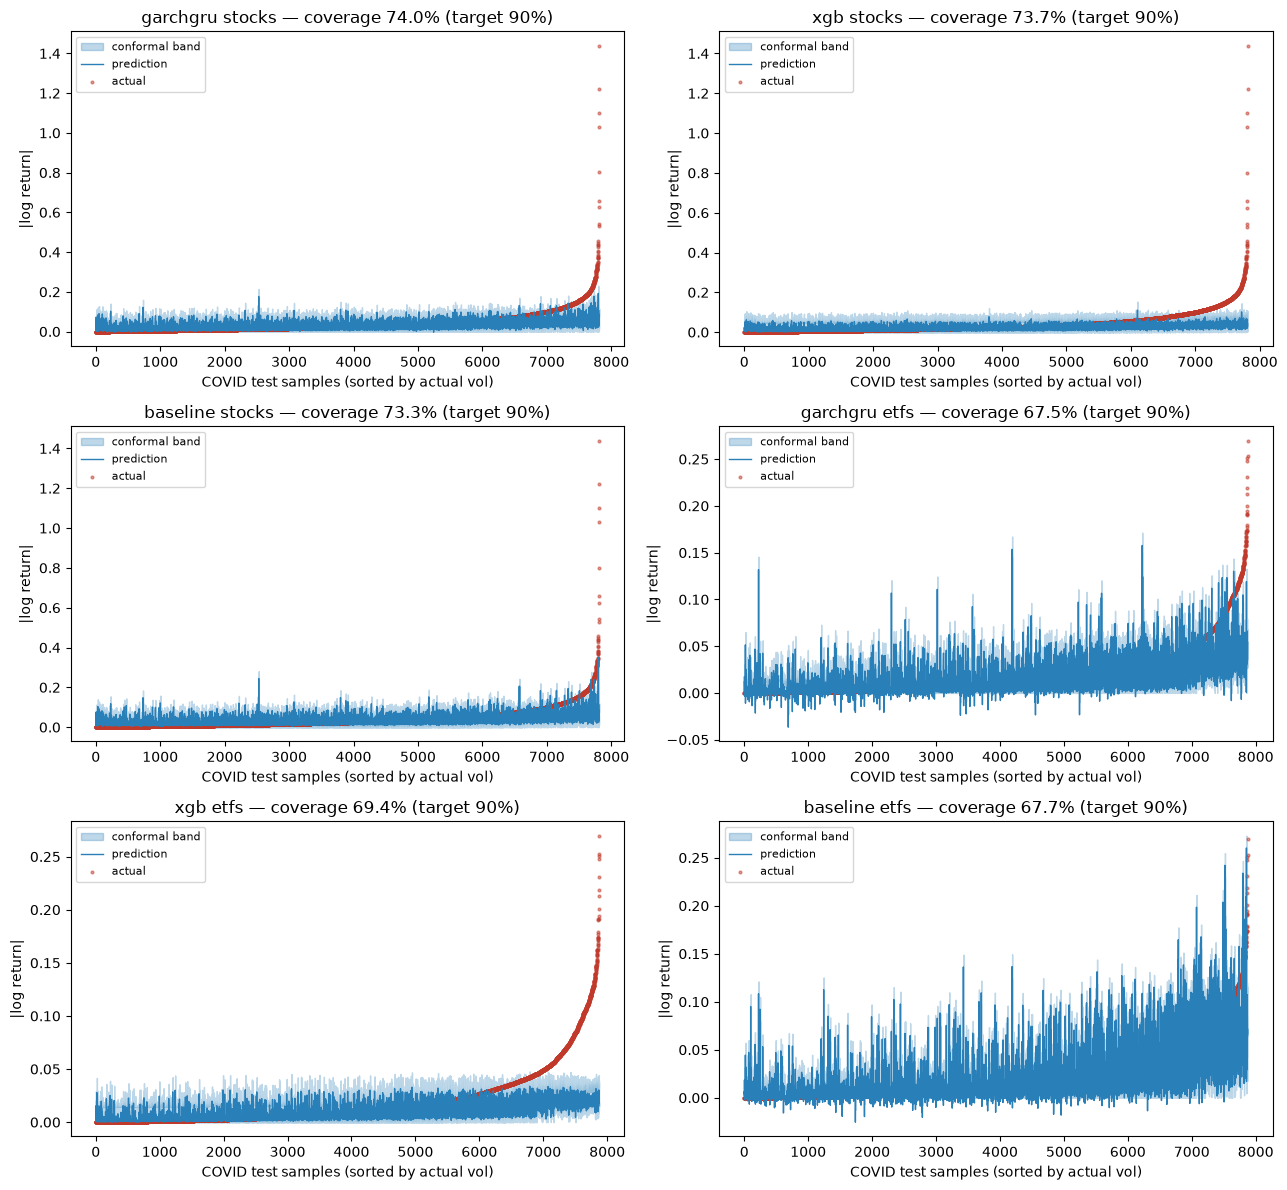

In [4]:
def plot_bands(payload: dict, ax) -> None:
    ti = payload["test_intervals"]
    y_true = np.array(ti["y_true"])
    y_pred = np.array(ti["y_pred"])
    lower = np.array(ti["lower"])
    upper = np.array(ti["upper"])
    order = np.argsort(y_true)
    x = np.arange(len(order))
    ax.fill_between(
        x, lower[order], upper[order], alpha=0.3, color="#2980b9", label="conformal band"
    )
    ax.plot(x, y_pred[order], color="#2980b9", lw=1, label="prediction")
    ax.scatter(x, y_true[order], s=4, color="#c0392b", alpha=0.5, label="actual")
    c = payload["conformal"]
    ax.set_title(
        f"{payload['architecture']} {payload['universe']} — "
        f"coverage {c['empirical_coverage']:.1%} (target {c['target_coverage']:.0%})"
    )
    ax.set_xlabel("COVID test samples (sorted by actual vol)")
    ax.set_ylabel("|log return|")
    ax.legend(loc="upper left", fontsize=8)

plot_payloads = [p for p in results.values()]
n = len(plot_payloads)
if n:
    ncols = 2
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    for payload, ax in zip(plot_payloads, axes.ravel()):
        plot_bands(payload, ax)
    plt.tight_layout()
    plt.show()

## 5) Product hook

For the app's turbulence alert, a champion's conformal artifact provides per-day `(lower, upper)` risk bands plus a scalar `coverage_gap` health metric. Suggested rule of thumb:

- `coverage_gap < 0.05` — bands are trustworthy, show them as-is.
- `0.05-0.15` — widen displayed bands (e.g. scale width by 1.5x) and flag "elevated uncertainty".
- `> 0.15` — regime shift: fall back to conservative coach rules (reduce-risk mode) regardless of point forecasts.